# Student Performance Analysis
### Data Analytics Project

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("StudentsPerformance.csv")

df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [3]:
print("Dataset Shape:", df.shape)

df.info()

Dataset Shape: (1000, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


In [4]:
# Checking Missing Values

print("Missing Values in Each Column:")
print(df.isnull().sum())

# Checking Duplicate Rows

print("\nDuplicate Rows:", df.duplicated().sum())

# Statistical Summary

df.describe()

Missing Values in Each Column:
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

Duplicate Rows: 0


,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [5]:
# Feature Engineering

df['total_score'] = (
    df['math score'] +
    df['reading score'] +
    df['writing score']
)

df['average_score'] = df['total_score'] / 3

# Display Updated Dataset

df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,total_score,average_score
0,female,group B,bachelor's degree,standard,none,72,72,74,218,72.666667
1,female,group C,some college,standard,completed,69,90,88,247,82.333333
2,female,group B,master's degree,standard,none,90,95,93,278,92.666667
3,male,group A,associate's degree,free/reduced,none,47,57,44,148,49.333333
4,male,group C,some college,standard,none,76,78,75,229,76.333333


In [6]:
# Student Performance Classification

def performance_category(score):
    if score >= 80:
        return 'Excellent'
    elif score >= 60:
        return 'Good'
    elif score >= 40:
        return 'Average'
    else:
        return 'Needs Improvement'

df['performance'] = df['average_score'].apply(performance_category)

# Display Results

df[['gender', 'average_score', 'performance']].head(10)

,gender,average_score,performance
0,female,72.666667,Good
1,female,82.333333,Excellent
2,female,92.666667,Excellent
3,male,49.333333,Average
4,male,76.333333,Good
5,female,77.333333,Good
6,female,91.666667,Excellent
7,male,40.666667,Average
8,male,65.000000,Good
9,female,49.333333,Average


gender
female    518
male      482
Name: count, dtype: int64


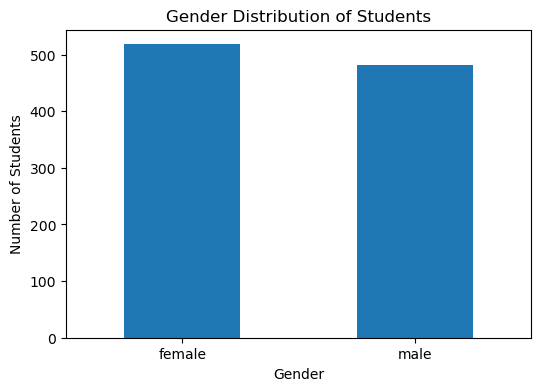

In [7]:
# Gender Distribution

gender_count = df['gender'].value_counts()

print(gender_count)

plt.figure(figsize=(6, 4))

gender_count.plot(kind='bar')

plt.title('Gender Distribution of Students')
plt.xlabel('Gender')
plt.ylabel('Number of Students')
plt.xticks(rotation=0)

plt.show()

        math score  reading score  writing score
gender                                          
female   63.633205      72.608108      72.467181
male     68.728216      65.473029      63.311203


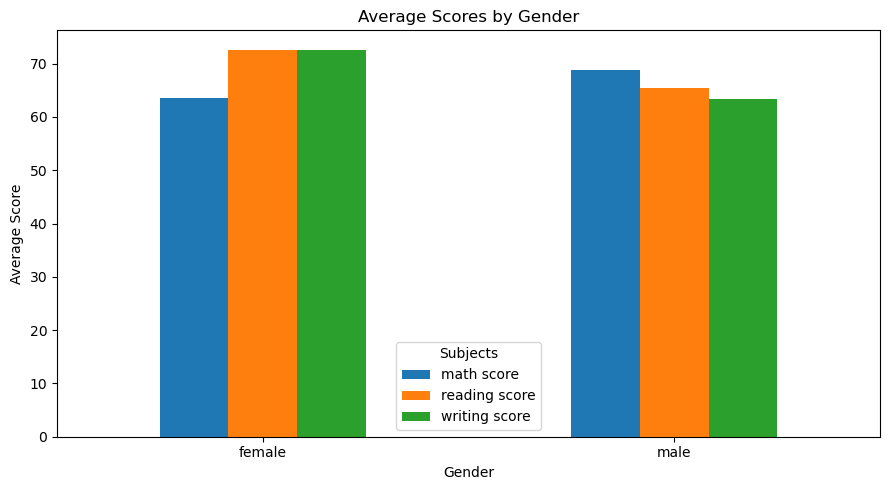

In [8]:
# Average Scores by Gender

gender_scores = df.groupby('gender')[
    ['math score', 'reading score', 'writing score']
].mean()

print(gender_scores)

gender_scores.plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title('Average Scores by Gender')
plt.xlabel('Gender')
plt.ylabel('Average Score')
plt.xticks(rotation=0)
plt.legend(title='Subjects')
plt.tight_layout()
plt.show()

                         math score  reading score  writing score
test preparation course                                          
completed                 69.695531      73.893855      74.418994
none                      64.077882      66.534268      64.504673


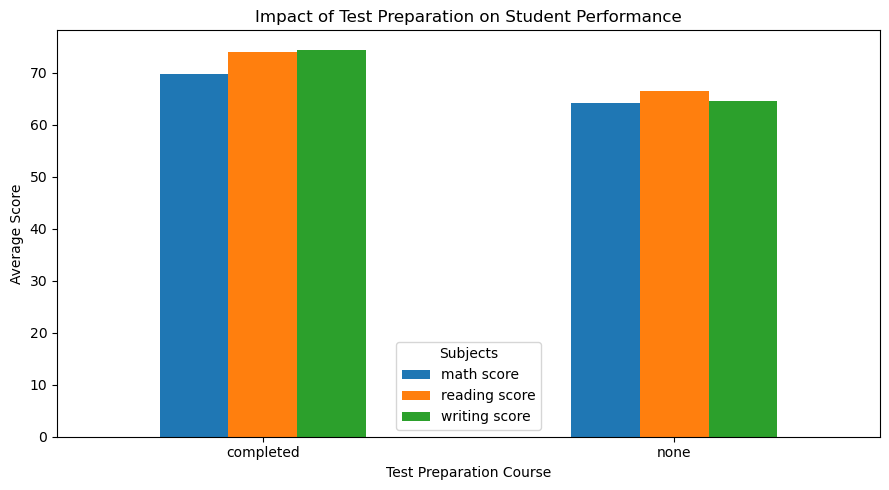

In [9]:
# Test Preparation Impact Analysis

prep_scores = df.groupby('test preparation course')[
    ['math score', 'reading score', 'writing score']
].mean()

print(prep_scores)

prep_scores.plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title('Impact of Test Preparation on Student Performance')
plt.xlabel('Test Preparation Course')
plt.ylabel('Average Score')
plt.xticks(rotation=0)
plt.legend(title='Subjects')
plt.tight_layout()
plt.show()

                             math score  reading score  writing score
parental level of education                                          
associate's degree            67.882883      70.927928      69.896396
bachelor's degree             69.389831      73.000000      73.381356
high school                   62.137755      64.704082      62.448980
master's degree               69.745763      75.372881      75.677966
some college                  67.128319      69.460177      68.840708
some high school              63.497207      66.938547      64.888268


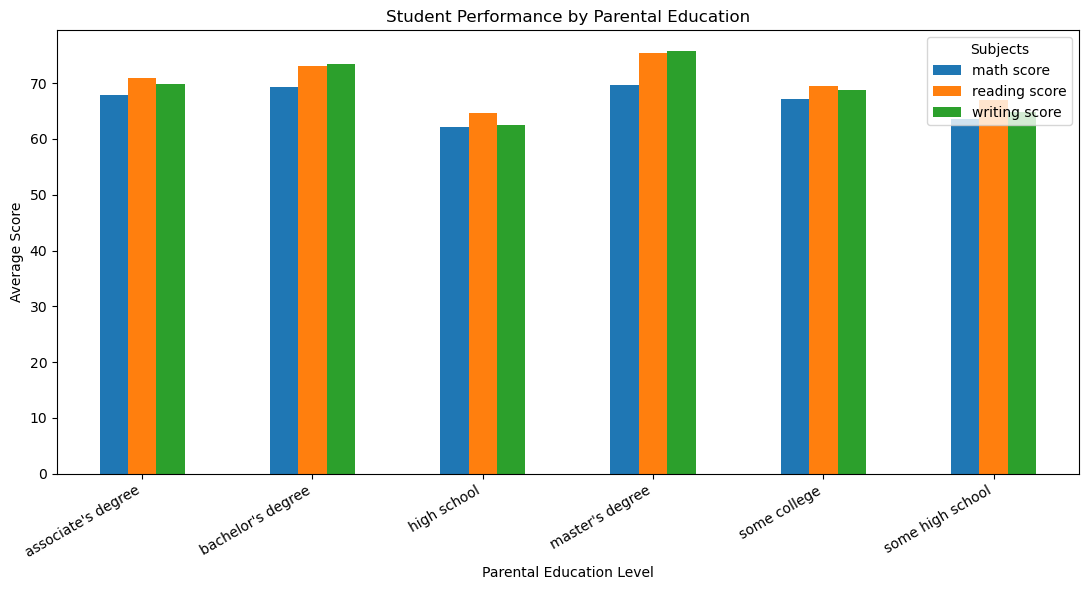

In [10]:
# Performance by Parental Education

parent_scores = df.groupby(
    'parental level of education'
)[['math score', 'reading score', 'writing score']].mean()

print(parent_scores)

parent_scores.plot(
    kind='bar',
    figsize=(11, 6)
)

plt.title('Student Performance by Parental Education')
plt.xlabel('Parental Education Level')
plt.ylabel('Average Score')
plt.xticks(rotation=30, ha='right')
plt.legend(title='Subjects')
plt.tight_layout()
plt.show()

              math score  reading score  writing score
lunch                                                 
free/reduced   58.921127      64.653521      63.022535
standard       70.034109      71.654264      70.823256


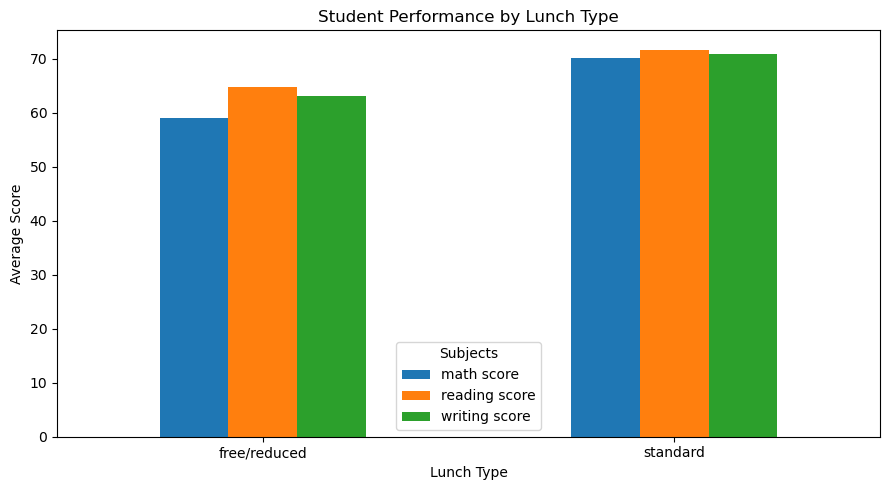

In [11]:
# Lunch Type Analysis

lunch_scores = df.groupby('lunch')[
    ['math score', 'reading score', 'writing score']
].mean()

print(lunch_scores)

lunch_scores.plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title('Student Performance by Lunch Type')
plt.xlabel('Lunch Type')
plt.ylabel('Average Score')
plt.xticks(rotation=0)
plt.legend(title='Subjects')
plt.tight_layout()
plt.show()

performance
Good                 517
Average              255
Excellent            198
Needs Improvement     30
Name: count, dtype: int64


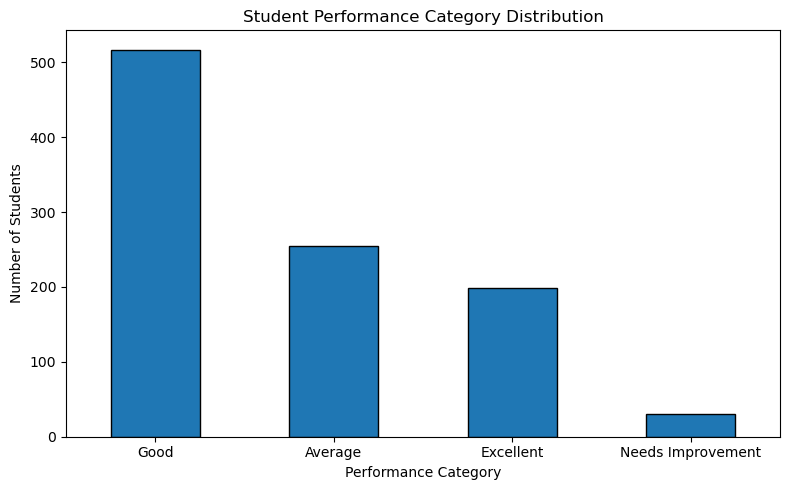

In [12]:
# Performance Category Distribution

performance_count = df['performance'].value_counts()

print(performance_count)

plt.figure(figsize=(8, 5))

performance_count.plot(
    kind='bar',
    edgecolor='black'
)

plt.title('Student Performance Category Distribution')
plt.xlabel('Performance Category')
plt.ylabel('Number of Students')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

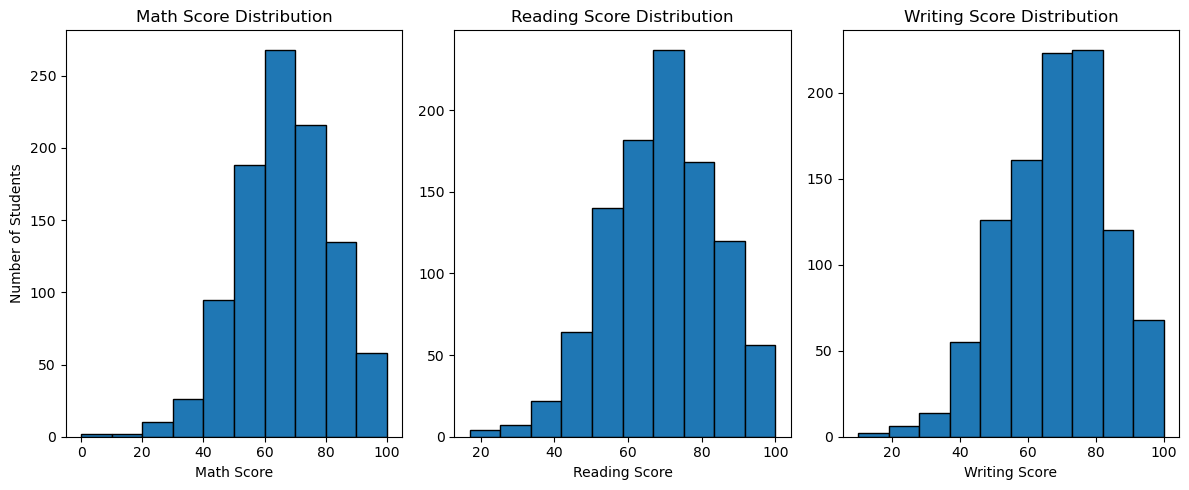

In [13]:
# Subject-wise Score Distribution

plt.figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
plt.hist(df['math score'], bins=10, edgecolor='black')
plt.title('Math Score Distribution')
plt.xlabel('Math Score')
plt.ylabel('Number of Students')

plt.subplot(1, 3, 2)
plt.hist(df['reading score'], bins=10, edgecolor='black')
plt.title('Reading Score Distribution')
plt.xlabel('Reading Score')

plt.subplot(1, 3, 3)
plt.hist(df['writing score'], bins=10, edgecolor='black')
plt.title('Writing Score Distribution')
plt.xlabel('Writing Score')

plt.tight_layout()
plt.show()

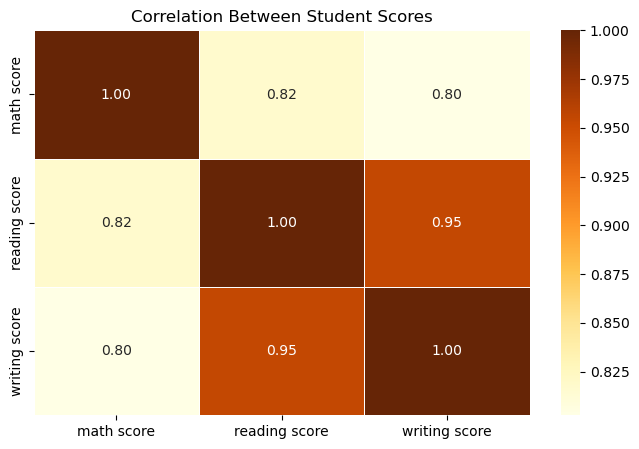

In [14]:
# Correlation Analysis

plt.figure(figsize=(8, 5))

correlation = df[['math score', 'reading score',
                  'writing score']].corr()

sns.heatmap(correlation, annot=True, cmap='YlOrBr',
            linewidths=0.5, fmt='.2f')

plt.title("Correlation Between Student Scores")
plt.show()

# Final Key Insights

In [15]:
print("KEY INSIGHTS FROM STUDENT PERFORMANCE ANALYSIS")

print("\n1. Average Scores:")
print(df[['math score', 'reading score', 'writing score']].mean().round(2))

print("\n2. Gender-wise Performance:")
print(df.groupby('gender')[['math score', 'reading score', 'writing score']].mean().round(2))

print("\n3. Test Preparation Impact:")
print(df.groupby('test preparation course')[
    ['math score', 'reading score', 'writing score']
].mean().round(2))

print("\n4. Lunch-wise Performance:")
print(df.groupby('lunch')[
    ['math score', 'reading score', 'writing score']
].mean().round(2))

print("\n5. Overall Performance Categories:")
print(df['performance'].value_counts())

KEY INSIGHTS FROM STUDENT PERFORMANCE ANALYSIS

1. Average Scores:
math score       66.09
reading score    69.17
writing score    68.05
dtype: float64

2. Gender-wise Performance:
        math score  reading score  writing score
gender                                          
female       63.63          72.61          72.47
male         68.73          65.47          63.31

3. Test Preparation Impact:
                         math score  reading score  writing score
test preparation course                                          
completed                     69.70          73.89          74.42
none                          64.08          66.53          64.50

4. Lunch-wise Performance:
              math score  reading score  writing score
lunch                                                 
free/reduced       58.92          64.65          63.02
standard           70.03          71.65          70.82

5. Overall Performance Categories:
performance
Good                 517
Average   

# Final Conclusion

The Student Performance Analysis project examined the academic performance of 1,000 students using Python, Pandas, Matplotlib, and Seaborn.

The analysis revealed the following findings:

1. The average scores were 66.09 in Mathematics, 69.17 in Reading, and 68.05 in Writing.
2. Female students performed better in Reading and Writing, whereas male students had a higher average in Mathematics.
3. Students who completed the test preparation course achieved higher average scores in all three subjects.
4. Students with standard lunch had higher average scores than students with free/reduced lunch.
5. Out of 1,000 students, 517 were categorized as Good, 255 as Average, 198 as Excellent, and 30 as Needs Improvement.
6. Reading and Writing scores showed the strongest positive correlation (0.95).

Overall, this project helped identify patterns and relationships in student academic performance and demonstrated how data analysis and visualization can support better educational insights.

In [16]:
df.to_csv("Student_Performance_Analysis.csv", index=False)

print("Dataset exported successfully!")

Dataset exported successfully!


In [17]:
# At-Risk Student Segmentation

at_risk_students = df[df['average_score'] < 40].copy()

print("Total At-Risk Students:", len(at_risk_students))

at_risk_students[
    ['gender', 'math score', 'reading score',
     'writing score', 'average_score', 'performance']
].head(10)

Total At-Risk Students: 30


,gender,math score,reading score,writing score,average_score,performance
17,female,18,32,28,26.000000,Needs Improvement
55,female,33,41,43,39.000000,Needs Improvement
59,female,0,17,10,9.000000,Needs Improvement
61,male,39,39,34,37.333333,Needs Improvement
66,male,45,37,37,39.666667,Needs Improvement
76,male,30,26,22,26.000000,Needs Improvement
84,male,42,39,34,38.333333,Needs Improvement
91,male,27,34,36,32.333333,Needs Improvement
145,female,22,39,33,31.333333,Needs Improvement
211,male,35,28,27,30.000000,Needs Improvement


In [18]:
# At-Risk Analysis

print("At-Risk Students by Gender:")
print(at_risk_students['gender'].value_counts())

print("\nAverage Scores of At-Risk Students:")
print(
    at_risk_students[
        ['math score', 'reading score', 'writing score']
    ].mean().round(2)
)

At-Risk Students by Gender:
gender
female    16
male      14
Name: count, dtype: int64

Average Scores of At-Risk Students:
math score       30.70
reading score    34.17
writing score    32.10
dtype: float64


In [19]:
at_risk_students.to_csv(
    "At_Risk_Students.csv",
    index=False
)

print("At-Risk Students Report Exported Successfully!")

At-Risk Students Report Exported Successfully!


# Principal's Report – Student Performance Analysis

## 1. Project Overview
This analysis examines the academic performance of 1,000 students across Mathematics, Reading, and Writing.

## 2. Key Findings
- The average Mathematics score is 66.09.
- The average Reading score is 69.17.
- The average Writing score is 68.05.
- Students who completed test preparation generally achieved higher average scores.
- Students with standard lunch had higher average scores than students with free/reduced lunch.
- Reading and Writing scores have a strong positive correlation (0.95).

## 3. At-Risk Student Analysis
A total of 30 students were identified as at-risk because their average score was below 40.
- Female students: 16
- Male students: 14

## 4. Conclusion
The analysis highlights differences in student performance across subjects and student groups. Test preparation, parental education, and lunch category show useful associations with academic scores. The identified at-risk students may benefit from additional academic support.

# Recommendations

Based on the analysis, the following recommendations are suggested:

### 1. Provide Additional Support to At-Risk Students
Identify students scoring below 40 in their average scores and provide extra classes, individual guidance, and regular progress monitoring.

### 2. Encourage Test Preparation
Motivate students to participate in test preparation programs through practice tests, revision sessions, and doubt-clearing classes.

### 3. Strengthen Subject-Wise Learning
Focus on improving Mathematics, Reading, and Writing skills through targeted practice, interactive learning activities, and regular assessments.

## Final Outcome
These recommendations can help improve academic performance, identify learning gaps, and provide better academic support to students.

In [20]:
df.to_csv("Student_Performance_Final.csv", index=False)

print("Final dataset exported successfully!")
print("Dataset Shape:", df.shape)
print(df.columns)

Final dataset exported successfully!
Dataset Shape: (1000, 11)
Index(['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course', 'math score', 'reading score',
       'writing score', 'total_score', 'average_score', 'performance'],
      dtype='object')


In [21]:
import os

print(os.getcwd())

C:\Users\Niharika Negi\Documents\Student_Performance_Analysis
